<div><center><img src="https://ml.ucv.ai/logo.png" width="150"/></center></div>

# Multi-Head Self-Attention paso a paso

En este notebook vamos a desarmar el `forward` de una capa de **atención multi-head** y a reconstruirlo a mano, operación por operación, con un poquito de matemática en cada paso.

La idea es simple: al final, nuestra versión manual tiene que dar **exactamente** lo mismo que el módulo. Si da igual, entendimos lo que hace.

Vamos a usar estas dimensiones en todo el notebook:

| Símbolo | Significado | Valor |
|---|---|---|
| $b$ | tamaño del batch | 2 |
| $n$ | número de tokens (p. ej. 16 parches + CLS en un ViT) | 17 |
| $D$ | dimensión del modelo | 64 |
| $h$ | número de cabezas | 8 |
| $d_k = D/h$ | dimensión de cada cabeza | 8 |

La entrada es $X \in \mathbb{R}^{b \times n \times D}$: cada fila $x_j \in \mathbb{R}^D$ es un token.

In [ ]:
# !pip install einops   # descomenta si estás en Colab y no la tienes
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from einops import rearrange

torch.manual_seed(0)

## 1. La clase

Esta es la implementación que vamos a estudiar. Fíjate que todo el `forward` son **cinco líneas**.

In [ ]:
class MultiHeadSelfAttention(nn.Module):
    '''Atención multi-head estándar sobre una secuencia de tokens.'''

    def __init__(self, dim, heads=8, dropout=0.0):
        super().__init__()
        assert dim % heads == 0, "dim debe ser divisible por heads"
        self.heads = heads
        self.escala = (dim // heads) ** -0.5                    # 1 / sqrt(d_k), con d_k = dim / heads
        self.to_qkv = nn.Linear(dim, dim * 3, bias=False)       # Q, K y V en una sola proyección
        self.to_out = nn.Sequential(nn.Linear(dim, dim), nn.Dropout(dropout))   # W_O

    def forward(self, x, return_attention=False):
        q, k, v = self.to_qkv(x).chunk(3, dim=-1)                                # (b, n, dim) cada una
        q, k, v = (rearrange(t, "b n (h d) -> b h n d", h=self.heads) for t in (q, k, v))
        attn = (torch.matmul(q, k.transpose(-1, -2)) * self.escala).softmax(dim=-1)   # (b, h, n, n)
        out = rearrange(torch.matmul(attn, v), "b h n d -> b n (h d)")           # concatenar las cabezas
        out = self.to_out(out)
        return (out, attn) if return_attention else out

In [ ]:
b, n, D, h = 2, 17, 64, 8
d_k = D // h

# eval() para que el dropout no haga nada
mhsa = MultiHeadSelfAttention(dim=D, heads=h).eval()
x = torch.randn(b, n, D)

salida, attn = mhsa(x, return_attention=True)
print("entrada :", tuple(x.shape))
print("salida  :", tuple(salida.shape))
print("atención:", tuple(attn.shape), "→ (batch, cabezas, n, n)")

entrada : (2, 17, 64)
salida  : (2, 17, 64)
atención: (2, 8, 17, 17) → (batch, cabezas, n, n)


La salida tiene **la misma forma que la entrada**. Eso no es casualidad: es lo que permite la conexión residual $X + \text{MHSA}(X)$ dentro de un bloque Transformer.

Ahora vamos a abrir la caja.

## 2. Paso 1: Proyección conjunta a Q, K y V

```python
q, k, v = self.to_qkv(x).chunk(3, dim=-1)
```

`to_qkv` es una sola capa lineal sin sesgo, $W_{QKV} \in \mathbb{R}^{D \times 3D}$. Partir la salida en tres pedazos es equivalente a tener tres matrices separadas:

$$
Q = XW_Q,\qquad K = XW_K,\qquad V = XW_V,\qquad W_Q, W_K, W_V \in \mathbb{R}^{D\times D}
$$

Se hace en una sola multiplicación porque es más eficiente en la GPU.

**Ojo con un detalle de PyTorch:** `nn.Linear` guarda el peso transpuesto, con forma `(salida, entrada)`, y calcula $y = xW^\top$. Por eso la matriz `to_qkv.weight` tiene forma `(192, 64)` y las filas `0:64` son $W_Q^\top$, las `64:128` son $W_K^\top$ y las `128:192` son $W_V^\top$.

In [ ]:
# (3D, D) = (192, 64)
W = mhsa.to_qkv.weight
print("to_qkv.weight:", tuple(W.shape))

# cada una (D, D)
W_Q, W_K, W_V = W[:D].T, W[D:2*D].T, W[2*D:].T

Q = x @ W_Q
K = x @ W_K
V = x @ W_V
print("Q, K, V:", tuple(Q.shape))

# Verificamos contra el módulo
q_mod, k_mod, v_mod = mhsa.to_qkv(x).chunk(3, dim=-1)
print("Q igual al del módulo?", torch.allclose(Q, q_mod, atol=1e-6))
print("K igual al del módulo?", torch.allclose(K, k_mod, atol=1e-6))
print("V igual al del módulo?", torch.allclose(V, v_mod, atol=1e-6))

to_qkv.weight: (192, 64)
Q, K, V: (2, 17, 64)
Q igual al del módulo? True
K igual al del módulo? True
V igual al del módulo? True


## 3. Paso 2: Partir en cabezas

```python
rearrange(t, "b n (h d) -> b h n d", h=self.heads)
```

Los 64 rasgos de cada token se leen como $8 \times 8$ (8 cabezas de 8 dimensiones) y el eje de cabezas se pasa para adelante:

$$
(b,\, n,\, h \cdot d_k) \;\longrightarrow\; (b,\, h,\, n,\, d_k) \qquad\text{es decir}\qquad (2, 17, 64) \to (2, 8, 17, 8)
$$

**No cambia ningún número, solo la forma.** Matemáticamente, la cabeza $i$ usa el bloque $i$ de 8 columnas de cada proyección:

$$
Q_i = XW_Q^{(i)},\qquad K_i = XW_K^{(i)},\qquad V_i = XW_V^{(i)},\qquad W^{(i)} \in \mathbb{R}^{D \times d_k}
$$

Cada cabeza trabaja en su propio subespacio de 8 dimensiones. Con el eje de cabezas adelante, PyTorch procesa las 8 cabezas en paralelo como si fueran parte del batch.

In [ ]:
Qh = rearrange(Q, "b n (h d) -> b h n d", h=h)
Kh = rearrange(K, "b n (h d) -> b h n d", h=h)
Vh = rearrange(V, "b n (h d) -> b h n d", h=h)
print("Q por cabezas:", tuple(Qh.shape))

# La cabeza i es exactamente el bloque de columnas [i*d_k : (i+1)*d_k]
i = 3
Q_i = x @ W_Q[:, i*d_k:(i+1)*d_k]
print(f"¿Cabeza {i} = X @ W_Q[:, {i*d_k}:{(i+1)*d_k}]?", torch.allclose(Qh[:, i], Q_i, atol=1e-6))

Q por cabezas: (2, 8, 17, 8)
¿Cabeza 3 = X @ W_Q[:, 24:32]? True


## 4. Paso 3: Puntajes y softmax: la matriz de atención

```python
attn = (torch.matmul(q, k.transpose(-1, -2)) * self.escala).softmax(dim=-1)
```

Para cada cabeza se calcula

$$
A_i = \text{softmax}\!\left(\frac{Q_i K_i^\top}{\sqrt{d_k}}\right) \in \mathbb{R}^{n \times n}
$$

y elemento a elemento:

$$
A_{i,\,jl} = \frac{\exp\!\left(q_j \cdot k_l / \sqrt{d_k}\right)}{\sum_{m=1}^{n} \exp\!\left(q_j \cdot k_m / \sqrt{d_k}\right)}
$$

- **Qué significa $q_j \cdot k_l$:** cuánto le interesa al token $j$ (el que pregunta) el token $l$ (el que ofrece información).
- **Por qué el softmax va en `dim=-1`:** normaliza sobre las *keys*, así que **cada fila suma 1**. Cada token obtiene una distribución de probabilidad sobre todos los tokens.
- **Por qué se divide entre $\sqrt{d_k}$:** lo vemos con un experimento en la siguiente sección.

In [ ]:
escala = d_k ** -0.5
# (b, h, n, n)
puntajes = (Qh @ Kh.transpose(-1, -2)) * escala
A = puntajes.softmax(dim=-1)
print("A:", tuple(A.shape))

print("Cada fila suma 1?", torch.allclose(A.sum(dim=-1), torch.ones(b, h, n), atol=1e-6))
print("A igual a la del módulo?", torch.allclose(A, attn, atol=1e-6))

A: (2, 8, 17, 17)
Cada fila suma 1? True
A igual a la del módulo? True


Veamos cómo se ve la atención de algunas cabezas. Cada fila $j$ es la distribución de atención del token $j$. Con pesos aleatorios (sin entrenar) los patrones no significan nada todavía, pero ya se nota que **cada cabeza atiende distinto**.

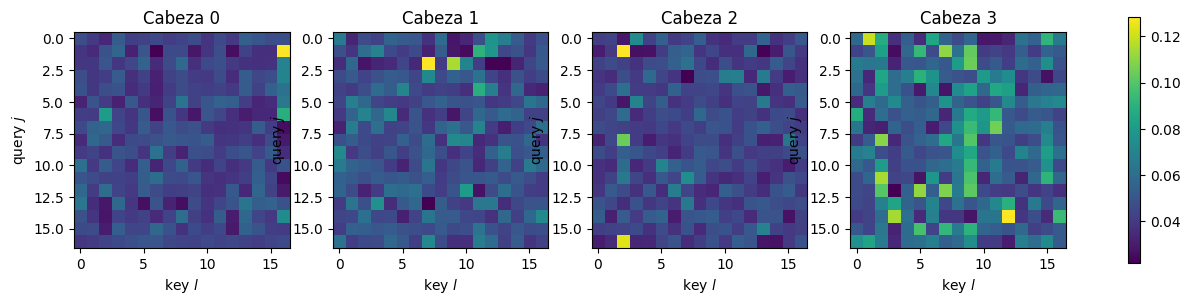

In [ ]:
fig, axs = plt.subplots(1, 4, figsize=(16, 4))
for c, ax in enumerate(axs):
    im = ax.imshow(A[0, c].detach(), cmap="viridis")
    ax.set_title(f"Cabeza {c}")
    ax.set_xlabel("key $l$")
    ax.set_ylabel("query $j$")
fig.colorbar(im, ax=axs, shrink=0.8)
plt.show()

### 4.1 ¿Por qué escalar con $1/\sqrt{d_k}$?

Supongamos que las componentes de $q$ y $k$ son independientes, con media 0 y varianza 1. Entonces

$$
q\cdot k = \sum_{t=1}^{d_k} q_t k_t, \qquad \operatorname{Var}(q\cdot k) = \sum_{t=1}^{d_k} \operatorname{Var}(q_t k_t) = d_k
$$

O sea, **la varianza del producto punto crece con $d_k$**. Logits muy grandes saturan el softmax: casi todo el peso se va a un solo token (casi one-hot) y los gradientes se vuelven prácticamente cero. Al dividir entre $\sqrt{d_k}$ la varianza vuelve a ser $\approx 1$.

Comprobémoslo:

In [ ]:
print(f"{'d_k':>5} | {'Var sin escalar':>15} | {'Var escalada':>12} | {'max prob. sin escalar':>21} | {'max prob. escalada':>18}")
for dk in [8, 64, 512]:
    q_ = torch.randn(2_000, n, dk)
    k_ = torch.randn(2_000, n, dk)
    s = (q_ @ k_.transpose(-1, -2))          # (2000, n, n)
    s_esc = s / dk ** 0.5
    pmax = s.softmax(-1).max(-1).values.mean()
    pmax_esc = s_esc.softmax(-1).max(-1).values.mean()
    print(f"{dk:>5} | {s.var():>15.1f} | {s_esc.var():>12.2f} | {pmax:>21.3f} | {pmax_esc:>18.3f}")

  d_k | Var sin escalar | Var escalada | max prob. sin escalar | max prob. escalada
    8 |             8.0 |         1.00 |                 0.558 |              0.233
   64 |            63.9 |         1.00 |                 0.842 |              0.238
  512 |           513.4 |         1.00 |                 0.946 |              0.239


Sin escalar, a medida que crece $d_k$ la probabilidad máxima se acerca a 1: el softmax se vuelve casi un *argmax*. Con la escala, la distribución se mantiene estable sin importar $d_k$.

## 5. Paso 4: Suma ponderada de los values y concatenación

```python
out = rearrange(torch.matmul(attn, v), "b h n d -> b n (h d)")
```

Para cada cabeza:

$$
\text{head}_i = A_i V_i \in \mathbb{R}^{n \times d_k}, \qquad \text{head}_{i,j} = \sum_{l=1}^{n} A_{i,\,jl}\, v_l
$$

Como cada fila de $A_i$ es no negativa y suma 1, **cada token de salida es una combinación convexa de los vectores value**: un promedio ponderado por la atención.

Después, el `rearrange` deshace el paso 2 y concatena las 8 cabezas en el eje de rasgos:

$$
\text{Concat}(\text{head}_1, \dots, \text{head}_h) \in \mathbb{R}^{n \times D}, \qquad (2, 8, 17, 8) \to (2, 17, 64)
$$

In [ ]:
cabezas = A @ Vh                                   # (b, h, n, d_k)
print("cabezas:", tuple(cabezas.shape))

# Verificamos la combinación convexa para un token j de la cabeza i
i, j = 2, 5
manual = sum(A[0, i, j, l] * Vh[0, i, l] for l in range(n))
print(f"head_{i},{j} = Σ_l A[{j},l]·v_l?", torch.allclose(manual, cabezas[0, i, j], atol=1e-6))

concat = rearrange(cabezas, "b h n d -> b n (h d)")
print("concat:", tuple(concat.shape))

# La cabeza i ocupa las columnas [i*d_k : (i+1)*d_k] de la concatenación
print("La cabeza 2 está en las columnas 16:24?", torch.equal(concat[..., 16:24], cabezas[:, 2]))

cabezas: (2, 8, 17, 8)
head_2,5 = Σ_l A[5,l]·v_l? True
concat: (2, 17, 64)
La cabeza 2 está en las columnas 16:24? True


## 6. Paso 5: Proyección de salida $W_O$ y dropout

```python
out = self.to_out(out)
```

$$
\text{MHSA}(X) = \text{Concat}(\text{head}_1,\dots,\text{head}_h)\,W_O + b_O, \qquad W_O \in \mathbb{R}^{D\times D}
$$

Hasta aquí las cabezas eran **independientes**: cada una vivía en su propio bloque de columnas. $W_O$ es lo que **mezcla la información de las distintas cabezas**. Después viene el dropout (que en `eval()` no hace nada).

Y ahora la prueba final: nuestra versión manual contra el módulo.

In [ ]:
W_O = mhsa.to_out[0].weight.T     # (D, D), recuerda que nn.Linear guarda W transpuesta
b_O = mhsa.to_out[0].bias

salida_manual = concat @ W_O + b_O
print("salida manual:", tuple(salida_manual.shape))
print("Salida manual = salida del módulo?", torch.allclose(salida_manual, salida, atol=1e-5))

salida manual: (2, 17, 64)
Salida manual = salida del módulo? True


## 7. Resumen

Todo el `forward` en una fórmula:

$$
\text{MHSA}(X) = \text{Concat}(\text{head}_1,\dots,\text{head}_h)\,W_O + b_O, \qquad \text{head}_i = \text{softmax}\!\left(\frac{Q_iK_i^\top}{\sqrt{d_k}}\right)V_i
$$

| Paso | Operación | Forma |
|---|---|---|
| entrada | $X$ | (2, 17, 64) |
| 1 | $Q, K, V = XW$ | 3 × (2, 17, 64) |
| 2 | partir en cabezas | 3 × (2, 8, 17, 8) |
| 3 | $A = \text{softmax}(QK^\top/\sqrt{d_k})$ | (2, 8, 17, 17) |
| 4 | $AV$ + concatenar | (2, 17, 64) |
| 5 | $W_O$ + dropout | (2, 17, 64) |

### Dos detalles para llevarse

- **Costo:** la matriz $n \times n$ hace que el costo sea $O(n^2 d)$ en tiempo y $O(h\,n^2)$ en memoria por ejemplo. Por eso un ViT trabaja con **parches** y no con píxeles: una imagen de $224 \times 224$ son 50 176 píxeles, pero solo 196 parches de $16 \times 16$.
- **Dónde va el dropout:** en esta implementación el dropout se aplica solo después de $W_O$, no sobre `attn`. Otras implementaciones (el Transformer original, `timm`) también le aplican dropout a los pesos de atención.